In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
data = pd.read_csv('anime.csv')


In [3]:
data['episodes'] = pd.to_numeric(data['episodes'], errors='coerce')
data['episodes'] = data['episodes'].fillna(data['episodes'].median())
data['rating'] = data['rating'].fillna(data['rating'].mean())


In [4]:
data


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266
...,...,...,...,...,...,...,...
12289,9316,Toushindai My Lover: Minami tai Mecha-Minami,Hentai,OVA,1.0,4.15,211
12290,5543,Under World,Hentai,OVA,1.0,4.28,183
12291,5621,Violence Gekiga David no Hoshi,Hentai,OVA,4.0,4.88,219
12292,6133,Violence Gekiga Shin David no Hoshi: Inma Dens...,Hentai,OVA,1.0,4.98,175


In [5]:
data.head(2)


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665


In [6]:
data.shape


(12294, 7)

In [7]:
data.columns


Index(['anime_id', 'name', 'genre', 'type', 'episodes', 'rating', 'members'], dtype='object')

In [8]:
data.info(10)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  float64
 5   rating    12294 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(2), int64(2), object(3)
memory usage: 672.5+ KB


In [9]:
data.describe()


,anime_id,episodes,rating,members
count,12294.000000,12294.000000,12294.000000,1.229400e+04
mean,14058.221653,12.095412,6.473902,1.807134e+04
std,11455.294701,46.244062,1.017096,5.482068e+04
min,1.000000,1.000000,1.670000,5.000000e+00
25%,3484.250000,1.000000,5.900000,2.250000e+02
50%,10260.500000,2.000000,6.550000,1.550000e+03
75%,24794.500000,12.000000,7.170000,9.437000e+03
max,34527.000000,1818.000000,10.000000,1.013917e+06


In [10]:
per_missing = (data.isnull().sum())
per_missing


anime_id     0
name         0
genre       62
type        25
episodes     0
rating       0
members      0
dtype: int64

In [11]:
data.drop_duplicates()


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266
...,...,...,...,...,...,...,...
12289,9316,Toushindai My Lover: Minami tai Mecha-Minami,Hentai,OVA,1.0,4.15,211
12290,5543,Under World,Hentai,OVA,1.0,4.28,183
12291,5621,Violence Gekiga David no Hoshi,Hentai,OVA,4.0,4.88,219
12292,6133,Violence Gekiga Shin David no Hoshi: Inma Dens...,Hentai,OVA,1.0,4.98,175


In [12]:
data.nlargest(10, "rating")[["type", "rating"]]


,type,rating
10464,Movie,10.00
10400,TV,9.60
9595,Movie,9.50
0,Movie,9.37
9078,Movie,9.33
1,TV,9.26
2,TV,9.25
10786,OVA,9.25
3,TV,9.17
4,TV,9.16


In [13]:
data.groupby('type')['rating'].mean()


type
Movie      6.321443
Music      5.588996
ONA        5.652120
OVA        6.375996
Special    6.523353
TV         6.889177
Name: rating, dtype: float64

In [14]:
data.groupby("type").head(10)


,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266
5,32935,Haikyuu!!: Karasuno Koukou VS Shiratorizawa Ga...,"Comedy, Drama, School, Shounen, Sports",TV,10.0,9.15,93351
6,11061,Hunter x Hunter (2011),"Action, Adventure, Shounen, Super Power",TV,148.0,9.13,425855
7,820,Ginga Eiyuu Densetsu,"Drama, Military, Sci-Fi, Space",OVA,110.0,9.11,80679
8,15335,Gintama Movie: Kanketsu-hen - Yorozuya yo Eien...,"Action, Comedy, Historical, Parody, Samurai, S...",Movie,1.0,9.10,72534
9,15417,Gintama&#039;: Enchousen,"Action, Comedy, Historical, Parody, Samurai, S...",TV,13.0,9.11,81109


In [15]:
data.groupby('type')['members'].sum().sort_values(ascending=False)


type
TV         161643014
Movie       24326080
OVA         19820109
Special     12865078
ONA          2711146
Music         640178
Name: members, dtype: int64

In [16]:
data.groupby('type')['rating'].mean().sort_values(ascending=False)


type
TV         6.889177
Special    6.523353
OVA        6.375996
Movie      6.321443
ONA        5.652120
Music      5.588996
Name: rating, dtype: float64

In [17]:
data.columns


Index(['anime_id', 'name', 'genre', 'type', 'episodes', 'rating', 'members'], dtype='object')

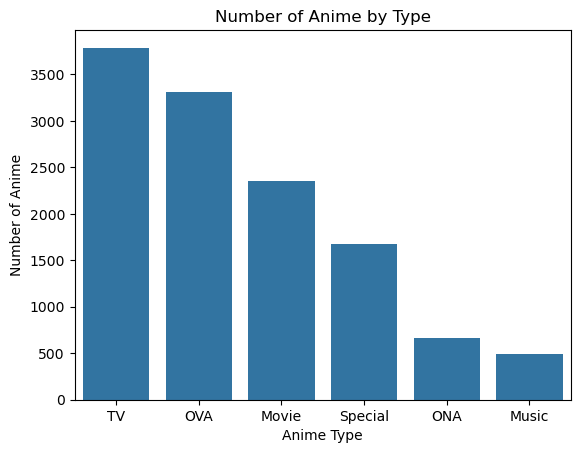

In [18]:
# Count anime by type
type_count = data["type"].value_counts()

# Bar chart
sns.barplot(x=type_count.index, y=type_count.values)

plt.title("Number of Anime by Type")
plt.xlabel("Anime Type")
plt.ylabel("Number of Anime")
plt.show()

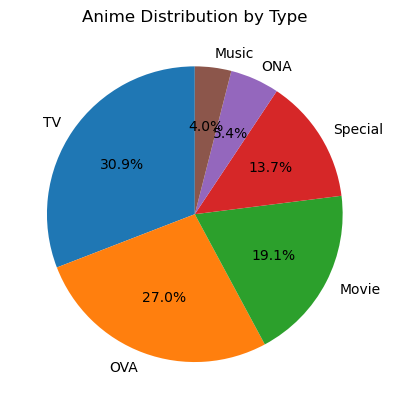

In [19]:
# Count anime by type
type_count = data["type"].value_counts()

# Pie chart
plt.pie(
    type_count.values,
    labels=type_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Anime Distribution by Type")
plt.show()

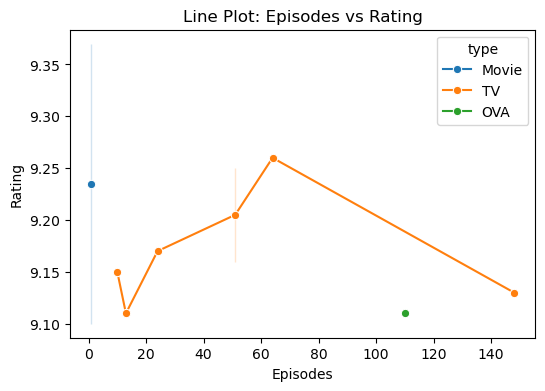

In [20]:
plt.figure(figsize=(6, 4))

top10 = data.head(10)

sns.lineplot(data=top10, x='episodes', y='rating', hue='type', marker='o')

plt.title("Line Plot: Episodes vs Rating")
plt.xlabel("Episodes")
plt.ylabel("Rating")

plt.show()


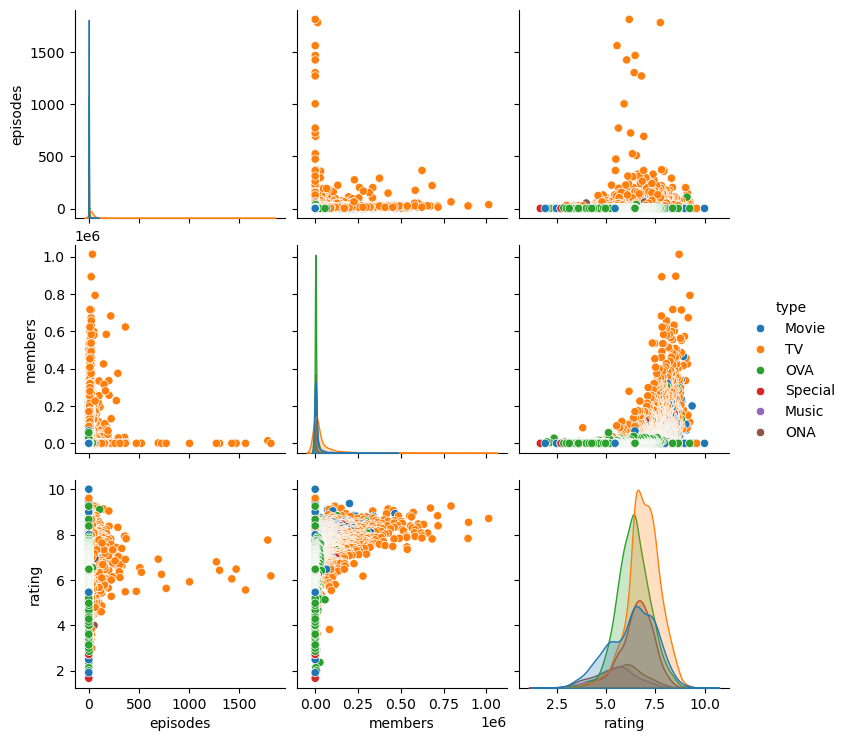

In [21]:
sns.pairplot(data,vars=['episodes', 'members', 'rating'],hue='type')

plt.show()


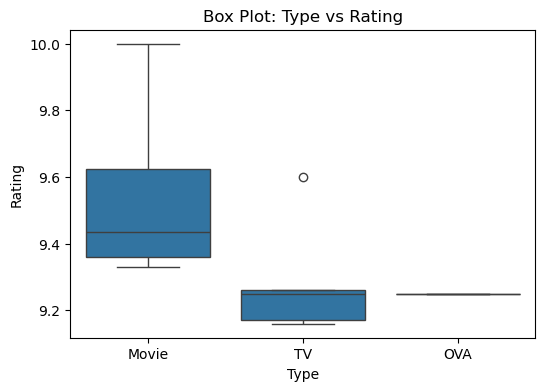

In [22]:

top10 = data.nlargest(10, "rating")

plt.figure(figsize=(6, 4))

sns.boxplot(data=top10, x='type', y='rating')

plt.title('Box Plot: Type vs Rating')
plt.xlabel('Type')
plt.ylabel('Rating')

plt.show()


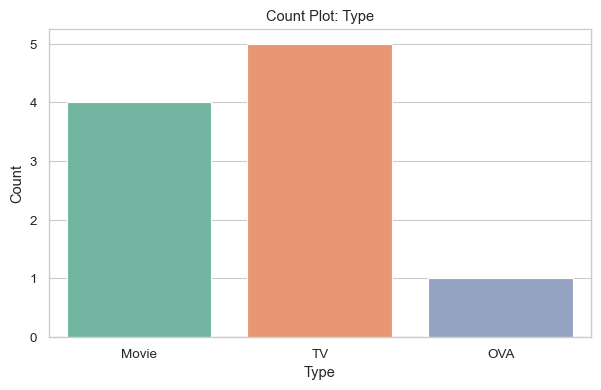

In [23]:
top10 = data.nlargest(10, "rating")

sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="Set1",
    font_scale=1.1
)

plt.figure(figsize=(7, 4))

sns.countplot(
    data=top10,
    x="type",
    hue="type",
    palette="Set2",
    legend=False
)

plt.title("Count Plot: Type")
plt.xlabel("Type")
plt.ylabel("Count")
plt.show()


C:\Users\ELCOT\AppData\Local\Temp\ipykernel_11256\2711171860.py:7: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=top10,x="rating",hue="type",fill=True,palette="coolwarm")


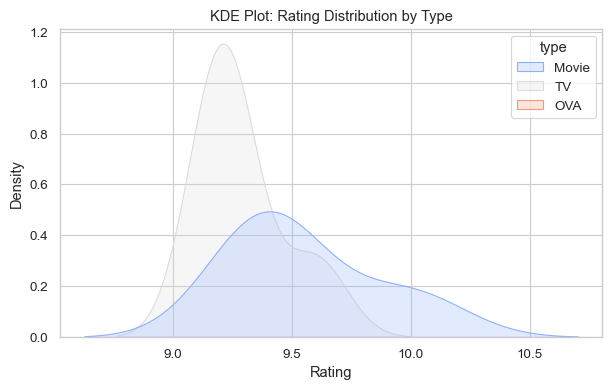

In [24]:
top10 = data.nlargest(10, "rating")

sns.set_theme(context="paper",style="whitegrid",palette="coolwarm",font_scale=1.1)

plt.figure(figsize=(7, 4))

sns.kdeplot(data=top10,x="rating",hue="type",fill=True,palette="coolwarm")

plt.title("KDE Plot: Rating Distribution by Type")
plt.xlabel("Rating")
plt.ylabel("Density")

plt.show()

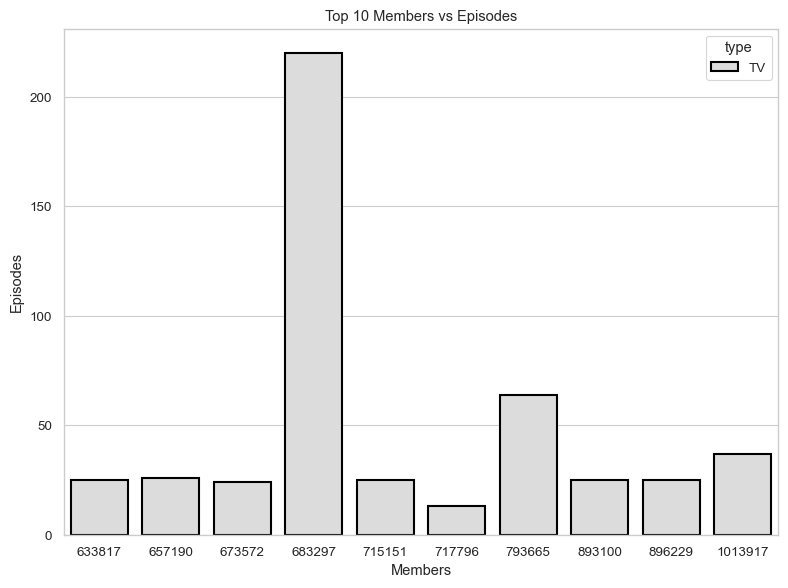

In [25]:
# Barplot

# Convert columns to numeric
data["members"] = pd.to_numeric(data["members"], errors="coerce")
data["episodes"] = pd.to_numeric(data["episodes"], errors="coerce")

# Get top 10 members
top_10 = data.nlargest(10, "members")

plt.figure(figsize=(8, 6))

sns.barplot(
    data=top_10,
    x="members",
    y="episodes",
    hue="type",
    palette="coolwarm",
    edgecolor="black",
    linewidth=1.5
)

plt.title("Top 10 Members vs Episodes")
plt.xlabel("Members")
plt.ylabel("Episodes")

plt.tight_layout()
plt.show()

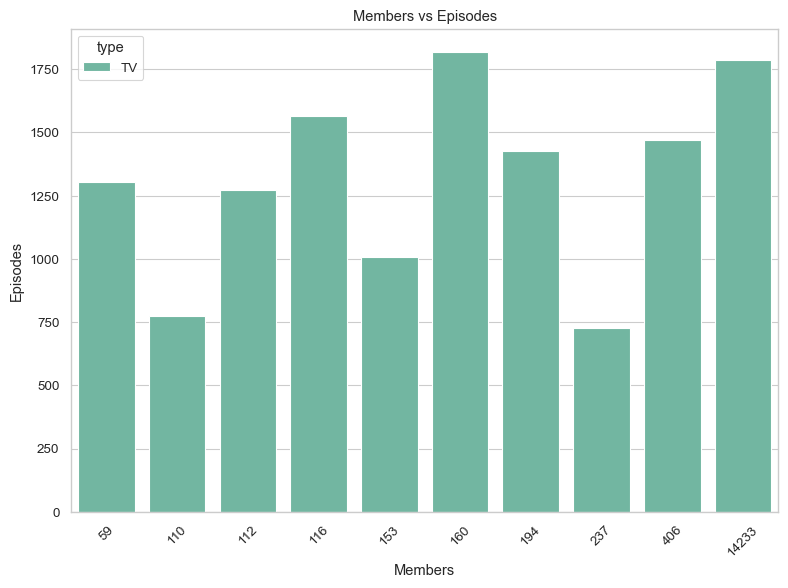

In [26]:
# Convert episodes to numeric
data["episodes"] = pd.to_numeric(data["episodes"], errors="coerce")

# Get top 10 based on episodes
top10 = data.nlargest(10, "episodes")

# Create chart
plt.figure(figsize=(8, 6))

sns.barplot(
    data=top10,
    x="members",
    y="episodes",
    hue="type",
    palette="Set2"
)

plt.title("Members vs Episodes")
plt.xlabel("Members")
plt.ylabel("Episodes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


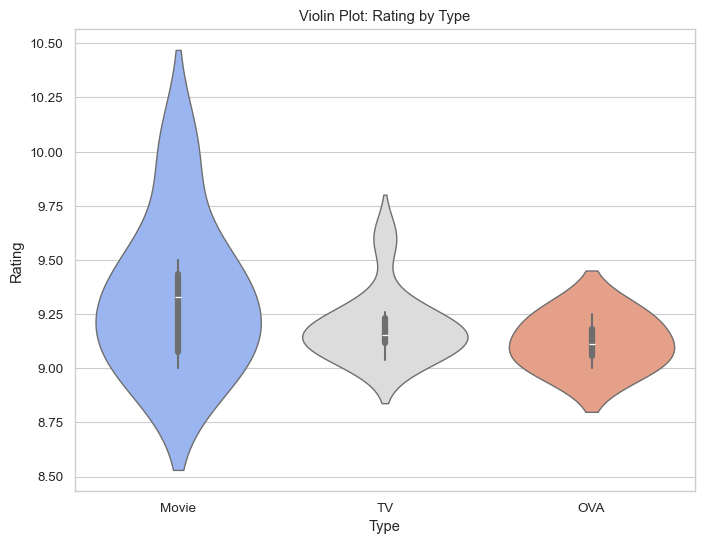

In [27]:
#violinplot

top10 = data.nlargest(20, "rating")

plt.figure(figsize=(8, 6))

sns.violinplot(
    data=top10,
    x="type",
    y="rating",
    hue="type",
    palette="coolwarm",
    legend=False
)

plt.title("Violin Plot: Rating by Type")
plt.xlabel("Type")
plt.ylabel("Rating")

plt.show()

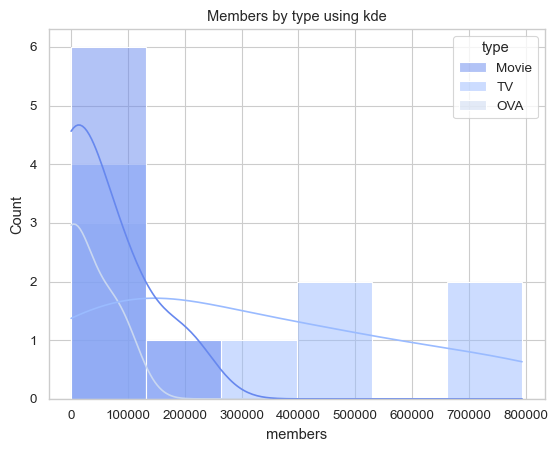

In [28]:
#histogram using Kernel Density Estimation
sns.histplot(data=top10, x="members", hue="type", kde=True)
plt.title("Members by type using kde")
plt.show()


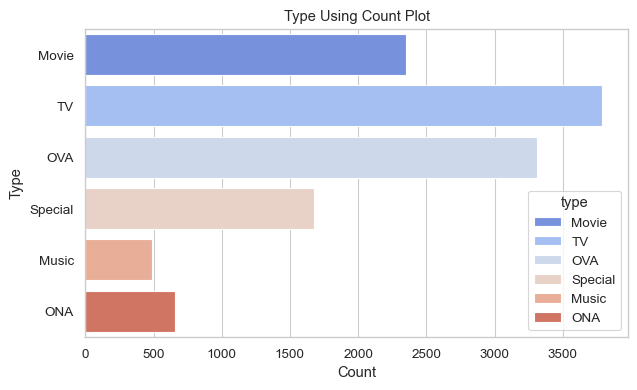

In [29]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    y="type",
    hue="type",
    palette="coolwarm",
    orient="h"
)

plt.title("Type Using Count Plot")
plt.xlabel("Count")
plt.ylabel("Type")

plt.show()


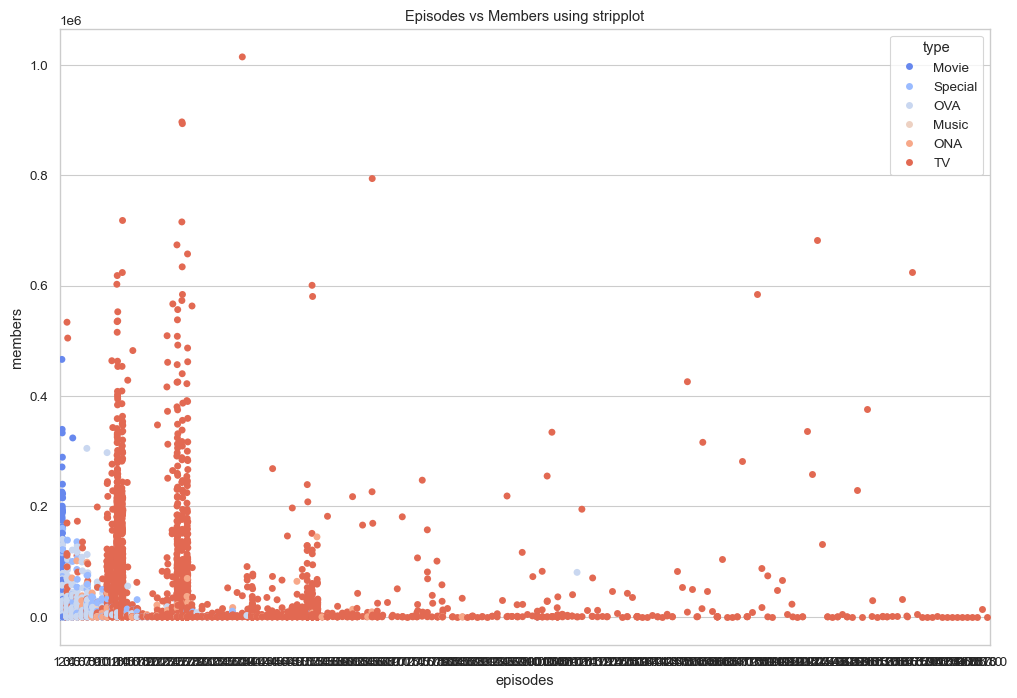

In [30]:
#stripplot
plt.figure(figsize=(12, 8))
sns.stripplot(data=data, x="episodes", y="members", hue="type", palette="coolwarm")
plt.title("Episodes vs Members using stripplot")
plt.show()


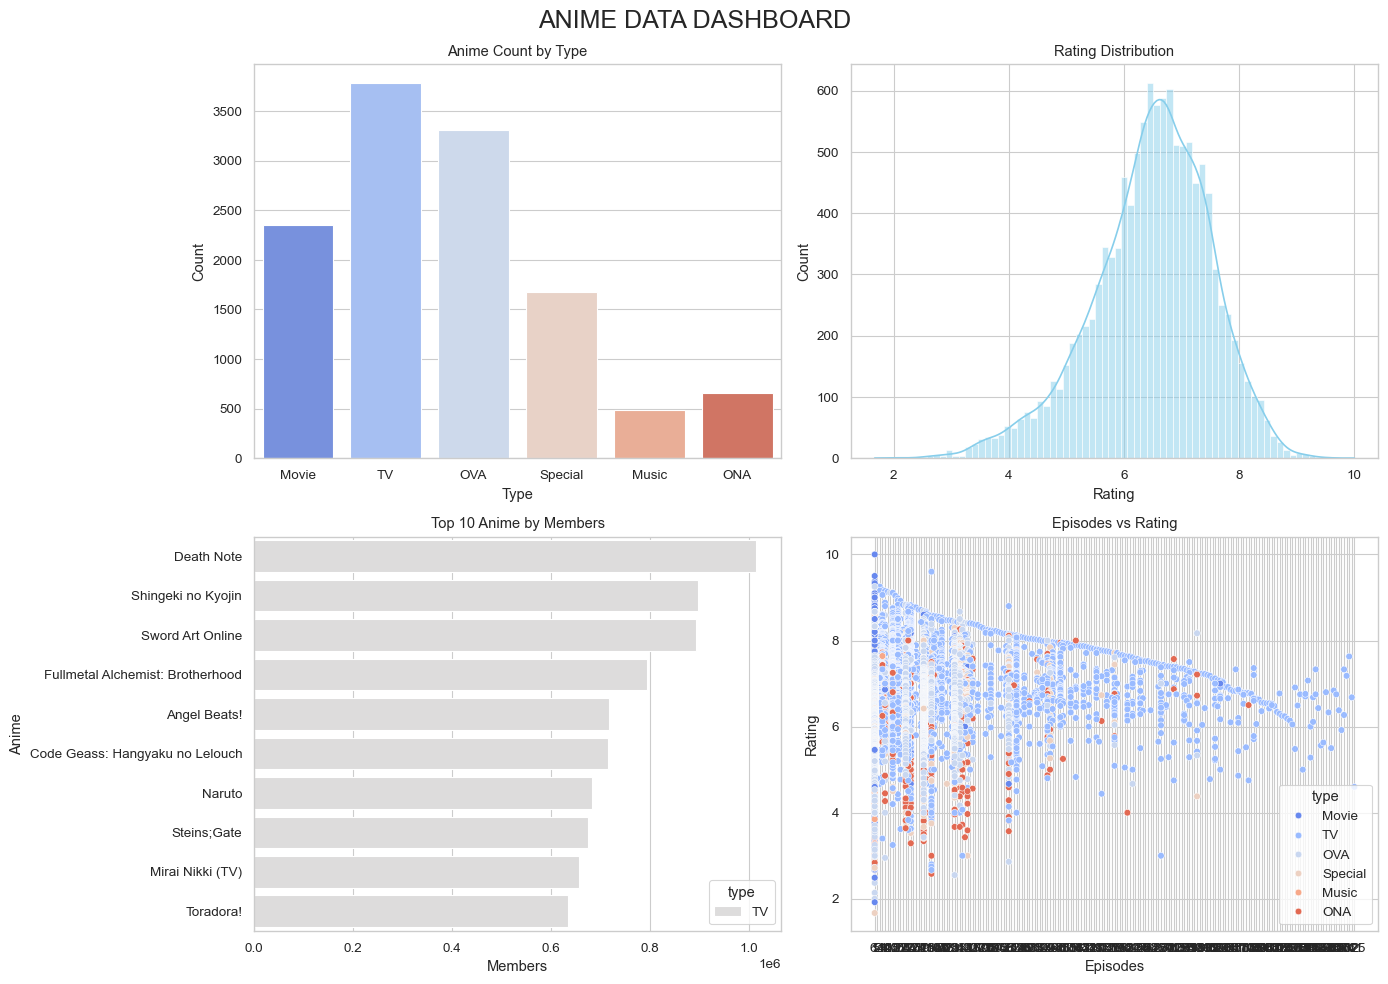

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("anime.csv")

plt.figure(figsize=(14, 10))

# 1. Count Plot
plt.subplot(2, 2, 1)

sns.countplot(
    data=data,
    x="type",
    hue="type",
    palette="coolwarm",
    legend=False
)

plt.title("Anime Count by Type")
plt.xlabel("Type")
plt.ylabel("Count")


# 2. Histogram
plt.subplot(2, 2, 2)

sns.histplot(
    data=data,
    x="rating",
    kde=True,
    color="skyblue"
)

plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")


# 3. Bar Plot
plt.subplot(2, 2, 3)

top10 = data.nlargest(10, "members")

sns.barplot(
    data=top10,
    x="members",
    y="name",
    hue="type",
    palette="coolwarm"
)

plt.title("Top 10 Anime by Members")
plt.xlabel("Members")
plt.ylabel("Anime")


# 4. Scatter Plot
plt.subplot(2, 2, 4)

sns.scatterplot(
    data=data,
    x="episodes",
    y="rating",
    hue="type",
    palette="coolwarm"
)

plt.title("Episodes vs Rating")
plt.xlabel("Episodes")
plt.ylabel("Rating")


plt.suptitle("ANIME DATA DASHBOARD", fontsize=18)

plt.tight_layout()
plt.show()

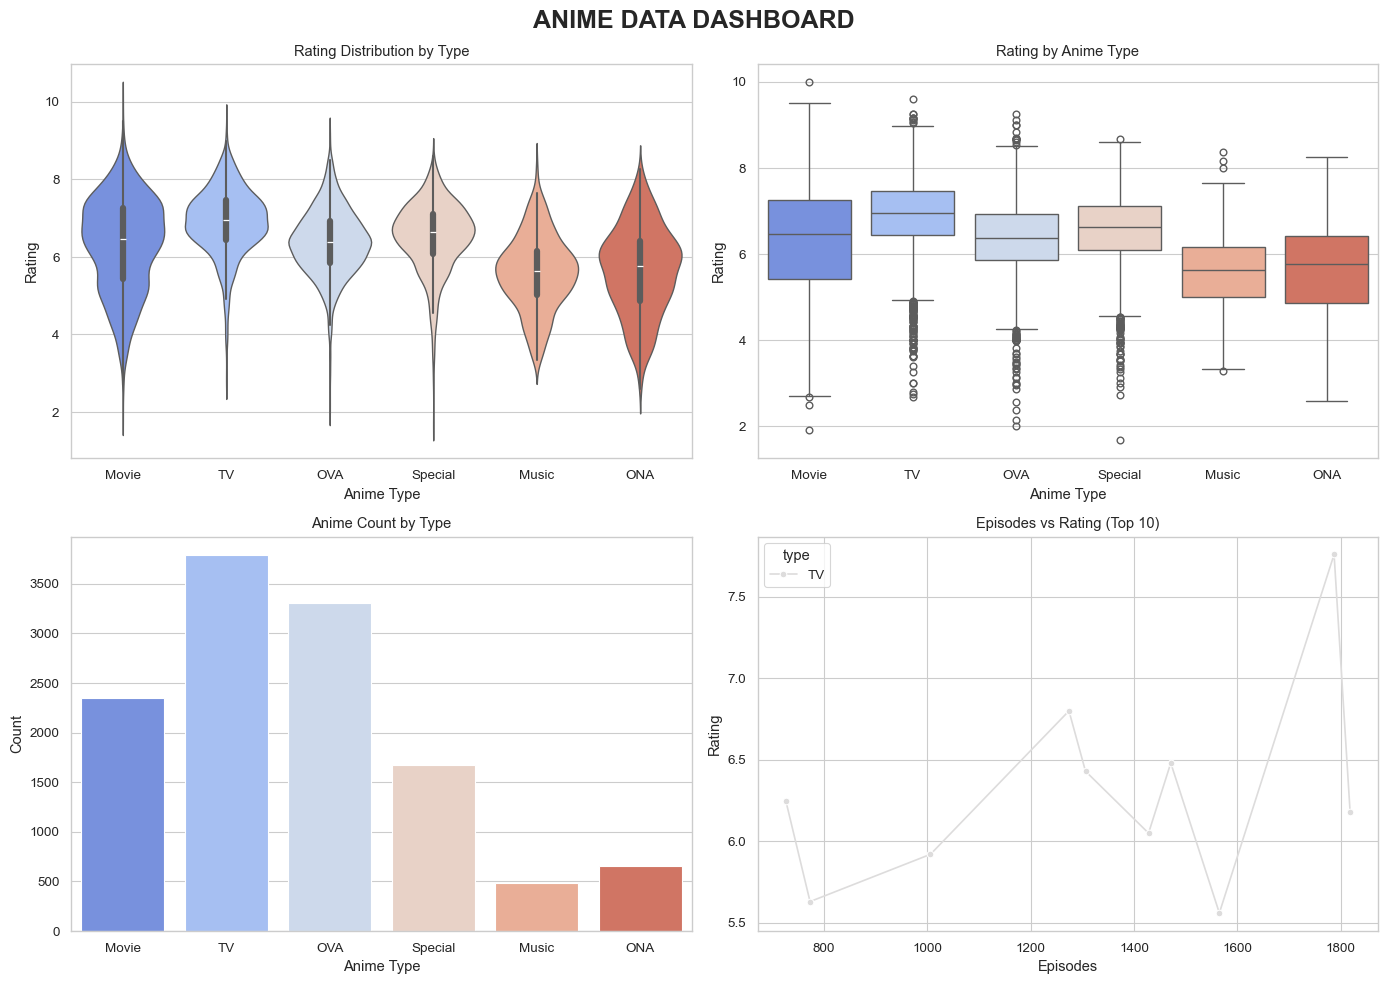

In [33]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
data = pd.read_csv("anime.csv")

# Convert columns to numeric
data["rating"] = pd.to_numeric(data["rating"], errors="coerce")
data["episodes"] = pd.to_numeric(data["episodes"], errors="coerce")

# Create dashboard
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# 1. Violin Plot
sns.violinplot(
    data=data,
    x="type",
    y="rating",
    hue="type",
    palette="coolwarm",
    ax=axs[0, 0],
    legend=False
)
axs[0, 0].set_title("Rating Distribution by Type")
axs[0, 0].set_xlabel("Anime Type")
axs[0, 0].set_ylabel("Rating")

# 2. Box Plot
sns.boxplot(
    data=data,
    x="type",
    y="rating",
    hue="type",
    palette="coolwarm",
    ax=axs[0, 1],
    legend=False
)
axs[0, 1].set_title("Rating by Anime Type")
axs[0, 1].set_xlabel("Anime Type")
axs[0, 1].set_ylabel("Rating")

# 3. Count Plot
sns.countplot(
    data=data,
    x="type",
    hue="type",
    palette="coolwarm",
    ax=axs[1, 0],
    legend=False
)
axs[1, 0].set_title("Anime Count by Type")
axs[1, 0].set_xlabel("Anime Type")
axs[1, 0].set_ylabel("Count")

# 4. Line Plot
top10 = (
    data.dropna(subset=["episodes", "rating"])
    .nlargest(10, "episodes")
    .sort_values("episodes")
)

sns.lineplot(
    data=top10,
    x="episodes",
    y="rating",
    hue="type",
    marker="o",
    palette="coolwarm",
    ax=axs[1, 1]
)
axs[1, 1].set_title("Episodes vs Rating (Top 10)")
axs[1, 1].set_xlabel("Episodes")
axs[1, 1].set_ylabel("Rating")

# Dashboard title
fig.suptitle("ANIME DATA DASHBOARD", fontsize=18, fontweight="bold")

plt.tight_layout()
plt.show()


Available columns: ['anime_id', 'name', 'genre', 'type', 'episodes', 'rating', 'members']
Matched columns: {'type': 'type', 'score': 'rating', 'episodes': 'episodes', 'members': 'members'}


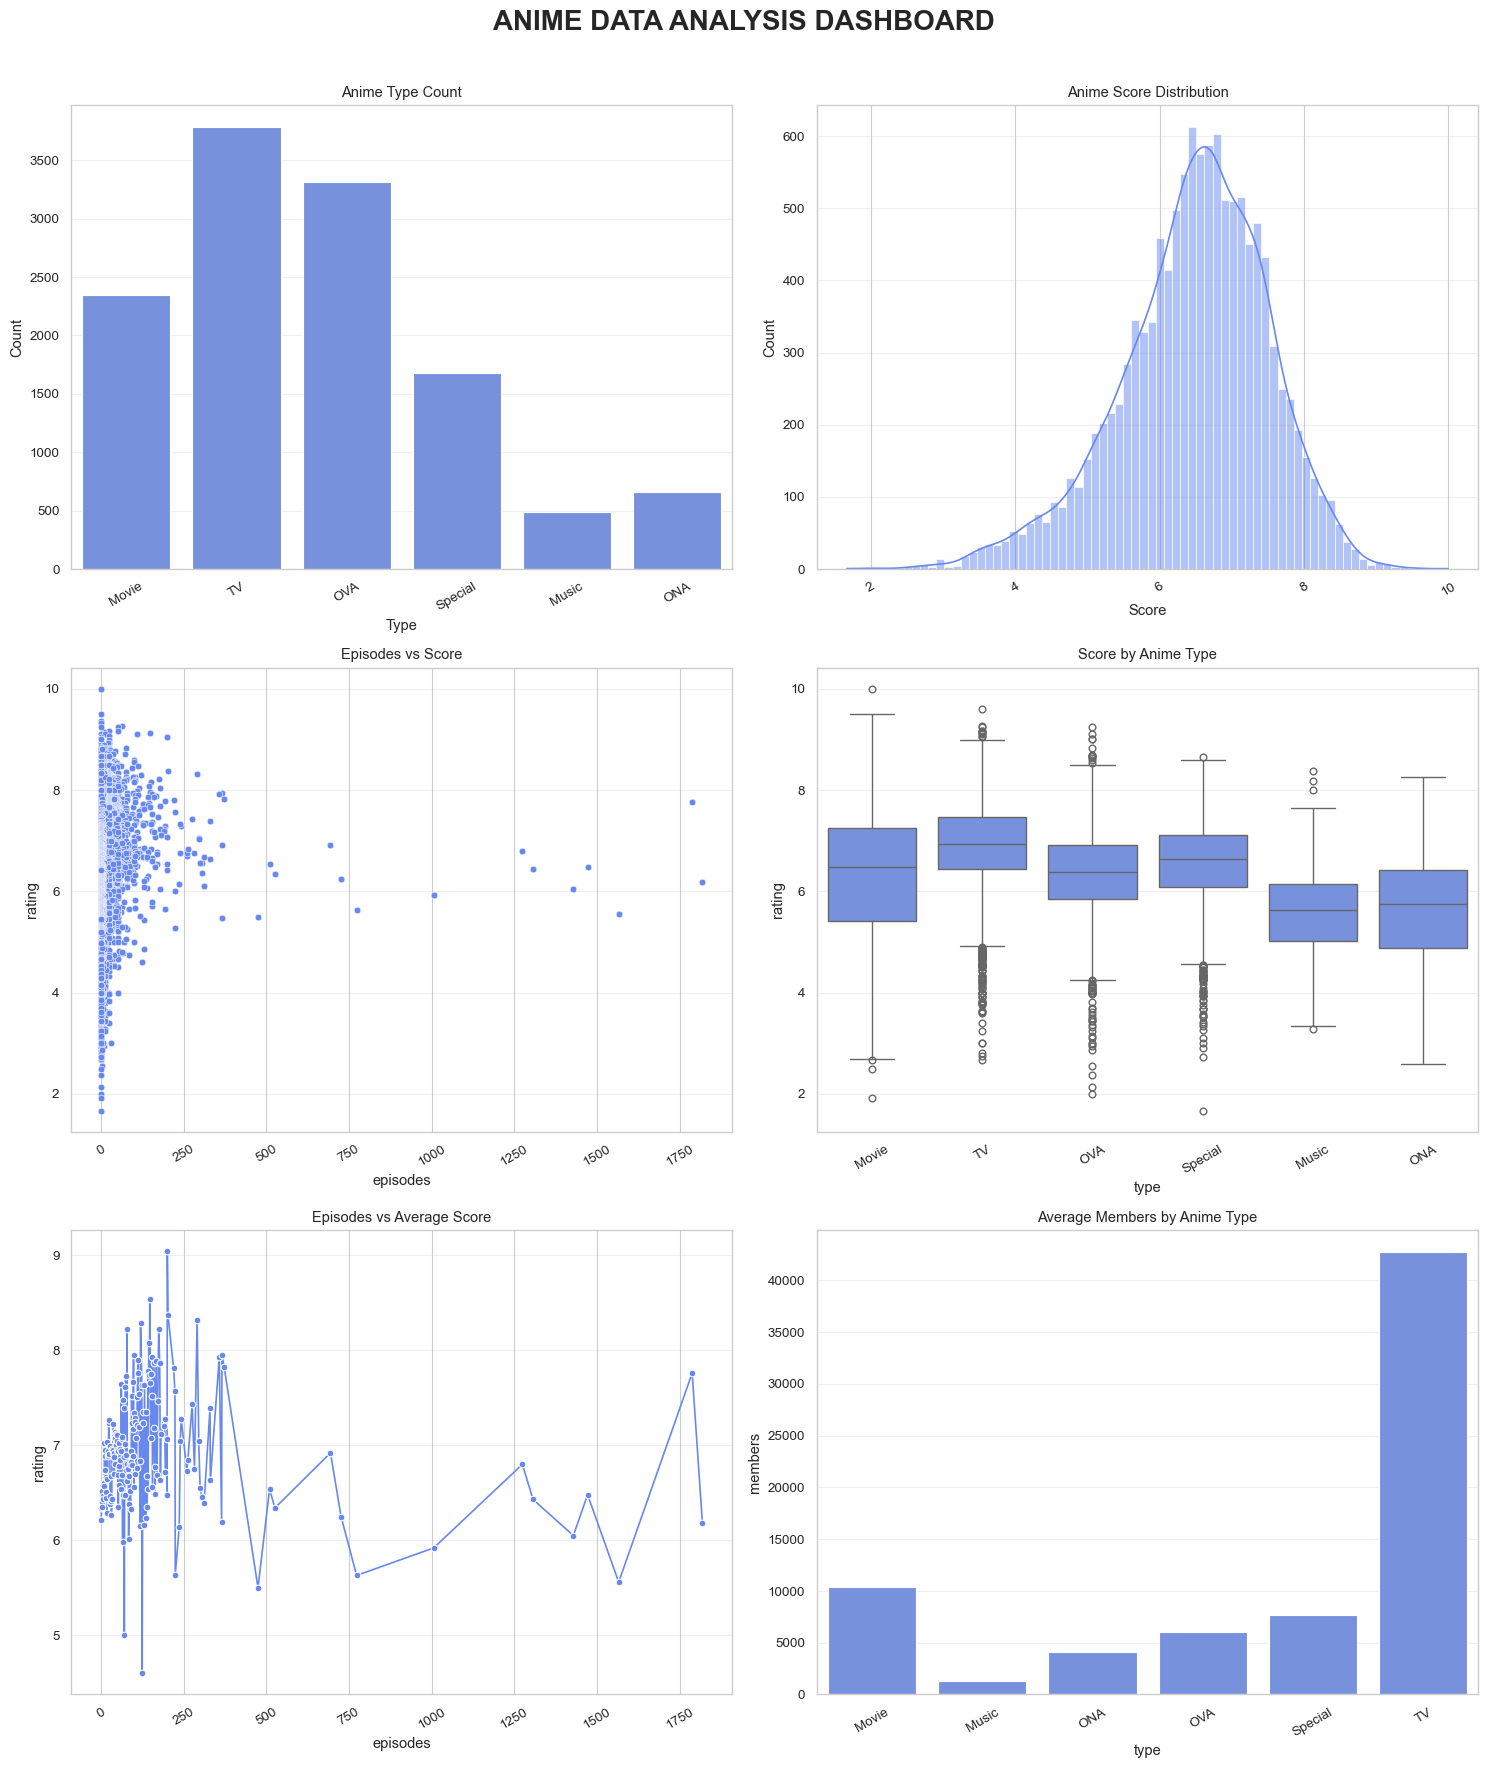

In [36]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("anime.csv")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Match available column names
column_options = {
    "type": ["type", "anime_type", "format"],
    "score": ["score", "rating", "user_rating"],
    "episodes": ["episodes", "episode", "episode_count"],
    "members": ["members", "member", "users", "favorites"]
}

selected = {}

for key, options in column_options.items():
    for col in options:
        if col in df.columns:
            selected[key] = col
            break

print("Available columns:", df.columns.tolist())
print("Matched columns:", selected)

# Check required columns
if not all(key in selected for key in column_options):
    print("Some required columns were not found.")
    print("Please check the Available columns printed above.")
else:
    # Convert numeric columns
    for key in ["score", "episodes", "members"]:
        df[selected[key]] = pd.to_numeric(
            df[selected[key]], errors="coerce"
        )

    # Create dashboard
    fig, axes = plt.subplots(3, 2, figsize=(15, 18))

    # Chart 1: Anime Type Count
    sns.countplot(data=df, x=selected["type"], ax=axes[0, 0])
    axes[0, 0].set_title("Anime Type Count")
    axes[0, 0].set_xlabel("Type")
    axes[0, 0].set_ylabel("Count")
    axes[0, 0].grid(axis="y", alpha=0.3)

    # Chart 2: Score Distribution
    sns.histplot(
        data=df.dropna(subset=[selected["score"]]),
        x=selected["score"], kde=True, ax=axes[0, 1]
    )
    axes[0, 1].set_title("Anime Score Distribution")
    axes[0, 1].set_xlabel("Score")
    axes[0, 1].set_ylabel("Count")

    # Chart 3: Episodes vs Score
    sns.scatterplot(
        data=df.dropna(
            subset=[selected["episodes"], selected["score"]]
        ),
        x=selected["episodes"],
        y=selected["score"],
        ax=axes[1, 0]
    )
    axes[1, 0].set_title("Episodes vs Score")

    # Chart 4: Score by Type
    sns.boxplot(
        data=df.dropna(
            subset=[selected["type"], selected["score"]]
        ),
        x=selected["type"],
        y=selected["score"],
        ax=axes[1, 1]
    )
    axes[1, 1].set_title("Score by Anime Type")

    # Chart 5: Average Score by Episode Count
    avg_score = (
        df.dropna(subset=[selected["episodes"], selected["score"]])
        .groupby(selected["episodes"], as_index=False)[selected["score"]]
        .mean()
        .sort_values(selected["episodes"])
    )

    sns.lineplot(
        data=avg_score,
        x=selected["episodes"],
        y=selected["score"],
        marker="o",
        ax=axes[2, 0]
    )
    axes[2, 0].set_title("Episodes vs Average Score")

    # Chart 6: Average Members by Type
    avg_members = (
        df.dropna(subset=[selected["type"], selected["members"]])
        .groupby(selected["type"], as_index=False)[selected["members"]]
        .mean()
    )

    sns.barplot(
        data=avg_members,
        x=selected["type"],
        y=selected["members"],
        ax=axes[2, 1]
    )
    axes[2, 1].set_title("Average Members by Anime Type")

    # Format dashboard
    for ax in axes.flat:
        ax.tick_params(axis="x", labelrotation=30)
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle(
        "ANIME DATA ANALYSIS DASHBOARD",
        fontsize=20,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
